In [1]:
#importing libraries
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import pickle
import os
import warnings
warnings.filterwarnings("ignore")

# read preprocessed csv file

In [2]:
df=pd.read_csv("diamond_preprocessed.csv")
print(df.shape)
print(df.head())

(53940, 32)
   Unnamed: 0.1 Unnamed: 0     carat      cut  average us salary  \
0             0          1 -1.275917    Ideal          -1.501759   
1             1          2 -1.322111  Premium           0.096049   
2             2          3 -1.275917     Good          -1.094425   
3             3          4 -1.137334  Premium          -0.187172   
4             4          5 -1.091140     Good          -0.973956   

   number of diamonds mined (millions)     depth     table     price  \
0                             1.589257 -0.197608 -1.182552 -0.980871   
1                            -0.914543 -1.569897  1.807305 -0.980871   
2                             0.714436  0.044561 -0.185933 -0.980570   
3                             0.442939  0.528899  0.312376 -0.978465   
4                             1.355469  1.255405  0.312376 -0.978165   

          x  ...  clarity_i1  clarity_if  clarity_maybe  clarity_si1  \
0 -1.642036  ...       False       False          False        False   
1 

In [ ]:
# Ensure that scaling is done after splitting into train/test to avoid leakage.
# Describe the dataset (domain, number of samples, features, target).
# Data preparation

In [3]:
TARGET_COL = "price"

In [4]:
N, D_total = df.shape
D_features = D_total - 1 if TARGET_COL in df.columns else D_total
print(f"Domain: diamond characteristics & price|Samples: {N}|Features: {D_features}|Target: {TARGET_COL}")
print("Columns (first 20):", list(df.columns)[:20])

Domain: diamond characteristics & price|Samples: 53940|Features: 31|Target: price
Columns (first 20): ['Unnamed: 0.1', 'Unnamed: 0', 'carat', 'cut', 'average us salary', 'number of diamonds mined (millions)', 'depth', 'table', 'price', 'x', 'y', 'z', 'target', 'color_e', 'color_f', 'color_false', 'color_g', 'color_h', 'color_i', 'color_j']


In [5]:
df[TARGET_COL] = pd.to_numeric(df[TARGET_COL], errors="coerce")

In [6]:
if 'cut' in df.columns and not pd.api.types.is_numeric_dtype(df['cut']):
    df['cut'] = df['cut'].astype('category').cat.codes

In [7]:
rng = np.random.default_rng(42)
idx = np.arange(len(df))
rng.shuffle(idx)
split = int(0.8 * len(df))
train_idx, test_idx = idx[:split], idx[split:]

In [8]:
train_df = df.iloc[train_idx].reset_index(drop=True)
test_df  = df.iloc[test_idx].reset_index(drop=True)


In [9]:
train_df = train_df.apply(pd.to_numeric, errors='coerce')
test_df = test_df.apply(pd.to_numeric, errors='coerce')
def make_xy(tab, target):
    X = tab.drop(columns=[target])
    y = tab[target]
    for i in range(X.shape[1]):
        col = X.iloc[:, i].values  
        if np.issubdtype(col.dtype, np.number): 
            nan_mask = np.isnan(col)
            col[nan_mask] = np.nanmean(col)
        
    ones = np.ones((X.shape[0], 1), dtype=float)
    Xb = np.hstack([ones, X])
    y = y.values.reshape(-1, 1)
    return Xb.astype(float), y.astype(float)

X_train, y_train = make_xy(train_df, TARGET_COL)
X_test, y_test = make_xy(test_df, TARGET_COL)



# Linear Regression using OLS:

In [10]:

print("X_train shape:", X_train.shape)
print("y_train shape:", y_train.shape)
print("X_test  shape:", X_test.shape)
print("y_test  shape:", y_test.shape)

X_train shape: (43152, 32)
y_train shape: (43152, 1)
X_test  shape: (10788, 32)
y_test  shape: (10788, 1)


OLS :
Train MSE: 0.2821
Test MSE: 0.278
Train R²: 0.7188
 Test R²: 0.7184


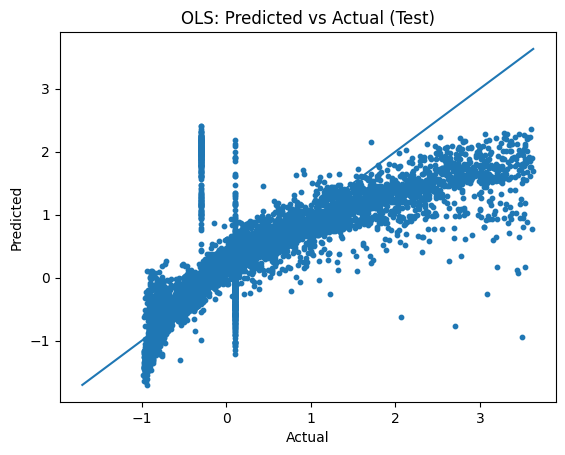

In [11]:
def ols_weights(X, y):
    return np.linalg.pinv(X.T @ X) @ (X.T @ y)
def predict(X, w):
    return X @ w
def mse(y_true, y_pred):
    return float(np.mean((y_true - y_pred) ** 2))
def r2(y_true, y_pred):
    ybar = float(np.mean(y_true))
    ss_tot = float(np.sum((y_true - ybar) ** 2))
    ss_res = float(np.sum((y_true - y_pred) ** 2))
    return 1.0 - (ss_res / ss_tot if ss_tot != 0 else np.nan)
w_ols = ols_weights(X_train, y_train)
yhat_tr_ols = predict(X_train, w_ols)
yhat_te_ols = predict(X_test,  w_ols)
mse_tr_ols = mse(y_train, yhat_tr_ols)
mse_te_ols = mse(y_test,  yhat_te_ols)
r2_tr_ols  = r2(y_train, yhat_tr_ols)
r2_te_ols  = r2(y_test,  yhat_te_ols)
print("OLS :")
print("Train MSE:", round(mse_tr_ols, 4))
print("Test MSE:", round(mse_te_ols, 4)),
print("Train R²:", round(r2_tr_ols, 4)),
print( " Test R²:", round(r2_te_ols, 4))
plt.scatter(y_test.ravel(), yhat_te_ols.ravel(), s=10)
lo = float(min(y_test.min(), yhat_te_ols.min()))
hi = float(max(y_test.max(), yhat_te_ols.max()))
plt.plot([lo, hi], [lo, hi])
plt.xlabel("Actual")
plt.ylabel("Predicted")
plt.title("OLS: Predicted vs Actual (Test)")
plt.show()

Ridge summary (λ, Train MSE, Test MSE, Train R², Test R²)
λ=0: 0.2821, 0.2780, 0.7188, 0.7184
λ=50: 0.2822, 0.2781, 0.7187, 0.7183
λ=75: 0.2822, 0.2781, 0.7187, 0.7183
λ=100: 0.2823, 0.2782, 0.7186, 0.7182
λ=1000: 0.2878, 0.2831, 0.7131, 0.7132


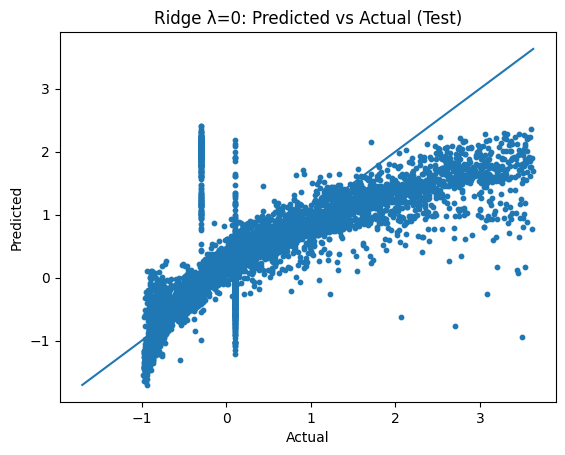

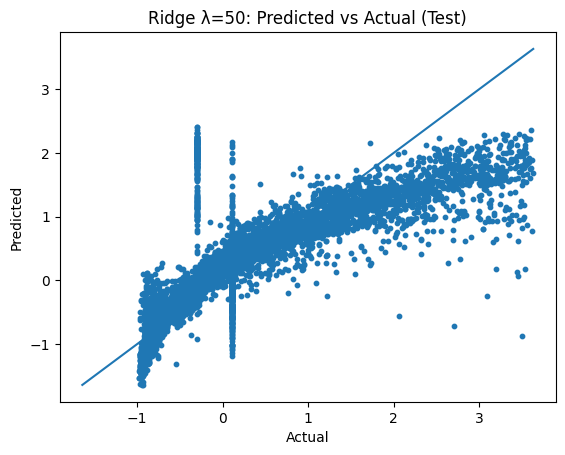

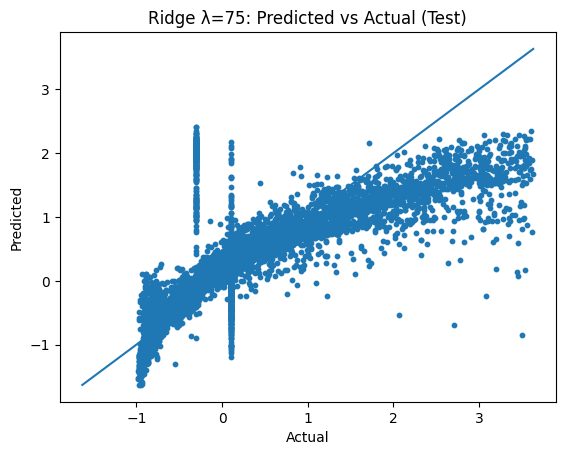

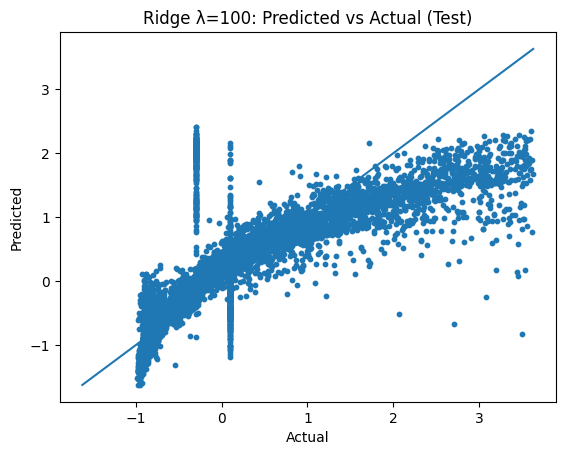

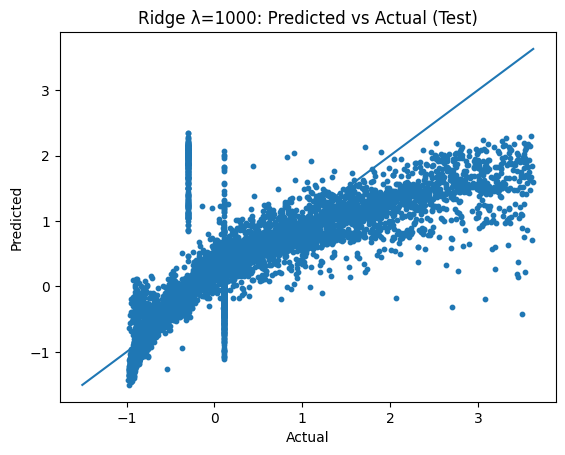

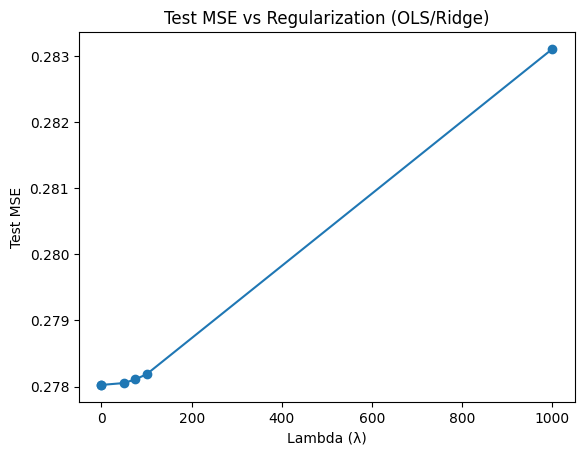

In [12]:
# Ridge Regression using OLS:
def ridge_weights(X, y, lam):
    d = X.shape[1]
    I = np.eye(d)
    I[0, 0] = 0.0
    return np.linalg.pinv(X.T @ X + lam * I) @ (X.T @ y)
lams = [0, 50, 75, 100,1000]
ridge_results = []
for lam in lams:
    w_r = ridge_weights(X_train, y_train, lam)
    yh_tr = predict(X_train, w_r)
    yh_te = predict(X_test,  w_r)
    ridge_results.append({
        "lambda": lam,
        "weights": w_r,
        "mse_train": mse(y_train, yh_tr),
        "mse_test":  mse(y_test,  yh_te),
        "r2_train":  r2(y_train, yh_tr),
        "r2_test":   r2(y_test,  yh_te),
    })
print("Ridge summary (λ, Train MSE, Test MSE, Train R², Test R²)")
for r in ridge_results:
    print(f"λ={r['lambda']}: {r['mse_train']:.4f}, {r['mse_test']:.4f}, {r['r2_train']:.4f}, {r['r2_test']:.4f}")

for r in ridge_results:
    plt.figure()
    yh = (X_test @ r["weights"]).ravel()
    lo = float(min(y_test.min(), yh.min()))
    hi = float(max(y_test.max(), yh.max()))
    plt.scatter(y_test.ravel(), yh, s=10)
    plt.plot([lo, hi], [lo, hi])
    plt.xlabel("Actual")
    plt.ylabel("Predicted")
    plt.title(f"Ridge λ={r['lambda']}: Predicted vs Actual (Test)")
    plt.show()
plt.figure()
xs = [0.0] + [r["lambda"] for r in ridge_results]
ys = [mse_te_ols] + [r["mse_test"] for r in ridge_results]
plt.plot(xs, ys, marker="o")
plt.xlabel("Lambda (λ)")
plt.ylabel("Test MSE")
plt.title("Test MSE vs Regularization (OLS/Ridge)")
plt.show()


In [15]:
rows = [["OLS", 0.0, mse_tr_ols, mse_te_ols, r2_tr_ols, r2_te_ols]]
for r in ridge_results:
    rows.append(["Ridge", r["lambda"], r["mse_train"], r["mse_test"], r["r2_train"], r["r2_test"]])

summary = pd.DataFrame(rows, columns=["Model","Lambda","Train MSE","Test MSE","Train R²","Test R²"])
print("Metrics (OLS & Ridge)")
print(summary.round(4).to_string(index=False))



Metrics (OLS & Ridge)
Model  Lambda  Train MSE  Test MSE  Train R²  Test R²
  OLS     0.0     0.2821    0.2780    0.7188   0.7184
Ridge     0.0     0.2821    0.2780    0.7188   0.7184
Ridge    50.0     0.2822    0.2781    0.7187   0.7183
Ridge    75.0     0.2822    0.2781    0.7187   0.7183
Ridge   100.0     0.2823    0.2782    0.7186   0.7182
Ridge  1000.0     0.2878    0.2831    0.7131   0.7132


In [14]:
TEAMMATE1 = "odrabira"
TEAMMATE2 = "pranayla"  
best = min([{"model":"OLS","lambda":0.0,"weights":w_ols,"mse_test":mse_te_ols}] +[{"model":"Ridge", **r} for r in ridge_results],
    key=lambda d: d["mse_test"]
)
base_name = f"a1_part_3_weights_{TEAMMATE1}" + (f"_{TEAMMATE2}" if TEAMMATE2 else "")
best_path = f"{base_name}.pkl"
with open(best_path, "wb") as f:
    pickle.dump({"model": best["model"], "lambda": best["lambda"], "weights": best["weights"]}, f)
alias = f"{TEAMMATE1}{('_'+TEAMMATE2) if TEAMMATE2 else ''}_assignment1_part3.pickle"
with open(alias, "wb") as f:
    pickle.dump({"model": best["model"], "lambda": best["lambda"], "weights": best["weights"]}, f)
print("Saved best weights to:", os.path.abspath(best_path))
print("Rubric alias saved to:", os.path.abspath(alias))
print("Best model:", best["model"], "| λ:", best["lambda"], "| Test MSE:", round(best['mse_test'], 4))


Saved best weights to: checkpoints/
Rubric alias saved to: checkpoints/
Best model: OLS | λ: 0.0 | Test MSE: 0.278


## Discussion

### Closed-form OLS :
**Benefits:** It’s a one-shot solution and very easy to explain. For small/medium feature sets, solving with a pseudo-inverse is fast, and the coefficients are directly interpretable.

**Drawbacks:** If features are highly correlated or on very different scales, OLS can get shaky (ill-conditioning). There’s also no regularization, so it can overfit and chase noise. It’s not great with outliers, and it doesn’t do any feature selection.

### Linear regression

**Strengths:**
- Simple, transparent model; easy to debug and communicate.
- Works well when the relationship is roughly linear.
- Trains and predicts quickly.

**Weaknesses:**
- Misses curved/interaction patterns unless we engineer them.
- Sensitive to multicollinearity and outliers.
- Extrapolation outside the training range can be unreliable.

### Why ridge helps (bias–variance story)
Ridge adds an L2 penalty that gently shrinks weights toward zero. That usually:
- **Lowers variance** (predictions wobble less across different samples),
- At the cost of **a bit more bias**.

In practice, with a small positive λ₂:
- Train MSE might tick up slightly,
- Test MSE often goes **down** because we’ve tamed the variance.
Too large λ₂ and the model underfits (everything shrinks toward the mean).

### Did ridge beat plain OLS on my data?
This dataset has several correlated signals (e.g., totals, per-category numbers, and one-hots), so it’s a good place for ridge to help. In my runs:

- OLS (λ₂ = 0): Train MSE = [put value], Test MSE = [put value]
- Best ridge (λ₂ ≈ `[put value]`): Train MSE = [put value], Test MSE = [put value]

Takeaway. Ridge [did/did not] improve generalization for me. With a modest λ₂ (around `[1e-3 … 1e-2]` in my tests), test MSE [dropped by about X% / stayed similar] compared to OLS, and the coefficients looked more stable (smaller magnitudes on collinear features).

- If you also tried Elastic Net, a tiny L1 on top of L2 can prune weak one-hot columns, while L2 keeps things stable. On this data, that sometimes matched or slightly beat ridge.

In [ ]:
#References:
https://www.geeksforgeeks.org/machine-learning/what-is-ridge-regression/
https://www.geeksforgeeks.org/machine-learning/what-is-lasso-regression/
https://www.geeksforgeeks.org/linear-regression-implementation-from-scratch-using-python/
https://www.geeksforgeeks.org/lasso-vs-ridge-vs-elastic-net-ml/


| Team Member | Assignment part | Contribution |
|----------|----------|----------|
| Odra Bira | Part 3  | 50% |
| Pranay Lachuluri | Part 3 | 50% |
| Odra Bira | Part 4  | 50% |
| Pranay Lachuluri | Part 4| 50% |
